In [32]:
# Employee Attrition Analysis
## 1. Introduction
#Goal: find out why employees leave and who is at risk.

In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [34]:
## 2. Data Overview

df.shape

(1470, 35)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [36]:
## 3. Attrition Rate

df['Attrition'].value_counts()  #how many employees left vs. stayed.
df['Attrition'].value_counts(normalize=True) * 100  #converts those proportions to percentages.
                                                          #83% stayed and 16%left

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

In [37]:
## 4. Data Cleaning
#Dropping columns that have a constant value or are only IDs.

df = df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1)
df.shape


#This step removes columns that add no useful information for analysis or modeling.

#EmployeeCount: always 1 for every row (constant).
#StandardHours: always 80 for every row (constant).
#Over18: always “Y” for every row (constant).
#EmployeeNumber: just an ID for each employee, with no predictive value.

(1470, 31)

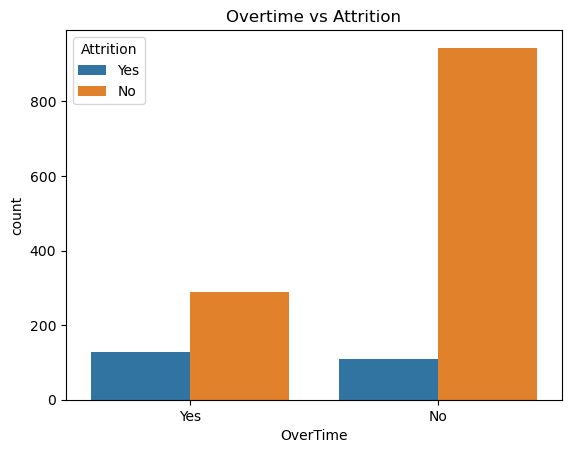

In [38]:
# 5. Exploratory Data Analysis (EDA)
# 5.1 Overtime vs Attrition

sns.countplot(x='OverTime', hue='Attrition', data=df)
plt.title("Overtime vs Attrition")
plt.show()


#sns.countplot(x='OverTime', hue='Attrition', data=df): puts OverTime (Yes/No) on the x-axis and counts the rows in each group. 

#hue='Attrition' splits each bar into two side-by-side bars, one for employees who stayed and one for those who left.

#plt.title("Overtime vs Attrition"): adds the chart title.

#plt.show(): displays the plot.

In [39]:
#**Insight:** Employees who work overtime show a noticeably higher attrition
#rate than those who do not. Although most employees do not work overtime,
#a large share of the people who left the company were in the overtime group. 
#This suggests that overtime is a key factor behind employee attrition.

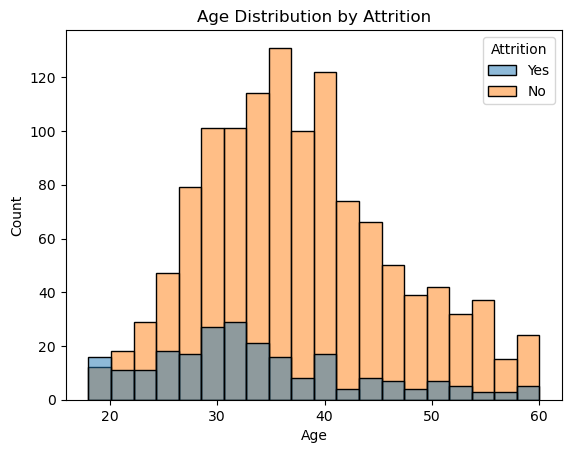

In [40]:
### 5.2 Age vs Attrition

sns.histplot(data=df, x='Age', hue='Attrition', bins=20)
plt.title("Age Distribution by Attrition")
plt.show()


#sns.histplot plots how many employees fall into each age bucket
#(bins=20 means 20 age ranges), and
#hue='Attrition' colors the bars for those who stayed and those who left so you can compare their age patterns.

In [41]:
### 5.3 Attrition Rate by Department

df.groupby('Department')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)


#df.groupby('Department'): splits the data into groups, one per department (e.g., Sales, Research & Development, Human Resources).
#['Attrition']: looks only at the Attrition column within each group.
#.apply(lambda x: ...): runs a small function on each group’s Attrition values.
#(x == 'Yes'): turns the values into True/False (True if the employee left).
#.mean(): the average of True/False is the fraction of True values, i.e. the share who left.
#* 100: converts that fraction to a percentage.

Department
Human Resources           19.047619
Research & Development    13.839750
Sales                     20.627803
Name: Attrition, dtype: float64

In [42]:
## 6. Data Preparation
#Creating new groups (income, tenure) to make the analysis easier to understand.

In [43]:
df['Attrition_Flag'] = (df['Attrition'] == 'Yes').astype(int)

df['IncomeGroup'] = pd.qcut(df['MonthlyIncome'], 4,
                            labels=['Low', 'Medium', 'High', 'Very High'])

df['TenureGroup'] = pd.cut(df['YearsAtCompany'], bins=[-1, 2, 5, 10, 40],
                           labels=['0-2 yrs', '3-5 yrs', '6-10 yrs', '10+ yrs'])

df[['Attrition_Flag', 'IncomeGroup', 'TenureGroup']].head()


#df['Attrition_Flag'] = (df['Attrition'] == 'Yes').astype(int): checks whether each employee left (True/False) and converts that to 1/0. This is useful for calculating attrition rates with .mean().
#pd.qcut(df['MonthlyIncome'], 4, labels=[...]): splits employees into 4 groups of roughly equal size (quartiles) based on income. The bottom 25% become Low, the next 25% Medium, then High, and the top 25% Very High.
#pd.cut(df['YearsAtCompany'], bins=[-1, 2, 5, 10, 40], labels=[...]): splits tenure into fixed ranges you define. The bins are (-1, 2], (2, 5], (5, 10] and (10, 40], so 0 to 2 years, 3 to 5, 6 to 10, and above 10. The -1 is there so that employees with 0 years are included.


#qcut makes groups with equal numbers of employees, but the income ranges are uneven.
#cut makes groups with the ranges you choose, but the number of employees per group can differ.

,Attrition_Flag,IncomeGroup,TenureGroup
0,1,High,6-10 yrs
1,0,High,6-10 yrs
2,1,Low,0-2 yrs
3,0,Low,6-10 yrs
4,0,Medium,0-2 yrs


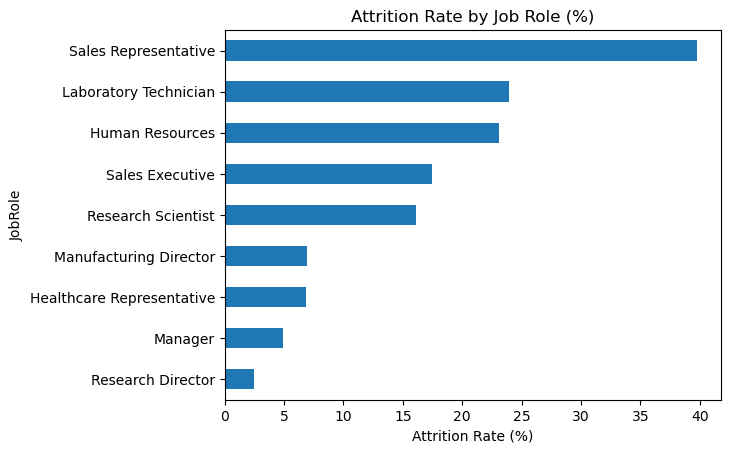

In [44]:
## 7. Deeper Analysis
### 7.1 Attrition by Job Role

(df.groupby('JobRole')['Attrition_Flag'].mean() * 100).sort_values().plot(kind='barh')
plt.title("Attrition Rate by Job Role (%)")
plt.xlabel("Attrition Rate (%)")
plt.show()


#df.groupby('JobRole')['Attrition_Flag'].mean(): groups employees by job role and takes the average of the 0/1 flag, which is the fraction who left.
#* 100: converts that fraction to a percentage.
#.sort_values(): sorts roles from lowest to highest attrition rate, so the highest ends up at the top of the chart.
#.plot(kind='barh'): draws horizontal bars, which suits long job role names better than vertical bars.


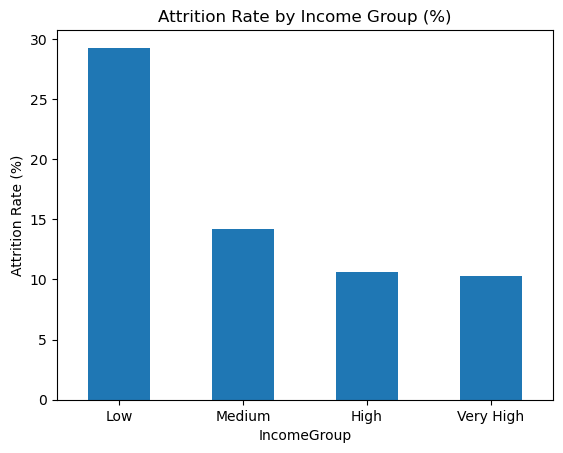

In [45]:
### 7.2 Attrition by Income Group

(df.groupby('IncomeGroup', observed=True)['Attrition_Flag'].mean() * 100).plot(kind='bar')
plt.title("Attrition Rate by Income Group (%)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.show()


#df.groupby('IncomeGroup', observed=True)['Attrition_Flag'].
#mean(): groups employees by income group and takes the average of the 0/1 flag, which is the fraction who left.
#observed=True means only groups that actually exist in the data are used, which avoids a pandas warning for categorical columns.
#.plot(kind='bar'): draws vertical bars, one per income group.
#plt.xticks(rotation=0): keeps the group names horizontal so they are easy to read.

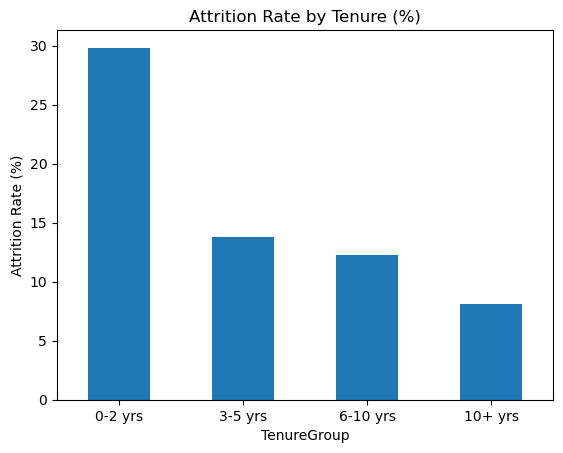

In [46]:
### 7.3 Attrition by Tenure

(df.groupby('TenureGroup', observed=True)['Attrition_Flag'].mean() * 100).plot(kind='bar')
plt.title("Attrition Rate by Tenure (%)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.show()

#df.groupby('TenureGroup', observed=True)['Attrition_Flag']
#.mean(): groups employees by tenure group and takes the average of the 0/1 flag, which is the fraction who left. 
#observed=True keeps only the groups that actually appear in the data.
#.plot(kind='bar'): draws one vertical bar per tenure group, in the order you defined in pd.cut.

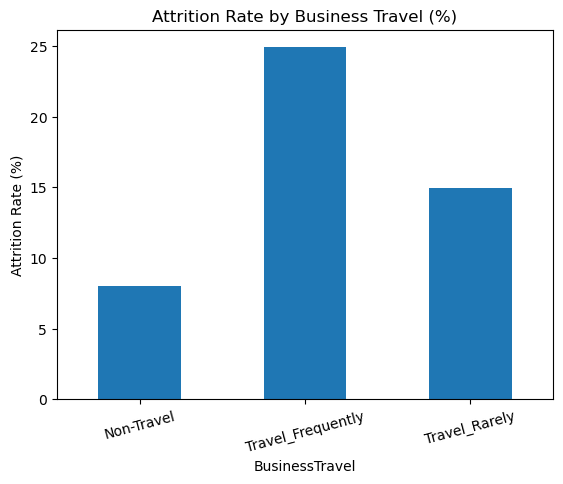

In [47]:
(df.groupby('BusinessTravel')['Attrition_Flag'].mean() * 100).plot(kind='bar')
plt.title("Attrition Rate by Business Travel (%)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.show()

#df.groupby('BusinessTravel')['Attrition_Flag'].mean(): groups employees by how often they travel for work and takes the average of the 0/1 flag, which is the fraction who left.

In [48]:
print("Overall attrition:", round(df['Attrition_Flag'].mean() * 100, 1), "%")
print()
print("By OverTime:")
print((df.groupby('OverTime')['Attrition_Flag'].mean() * 100).round(1))
print()
print("By Job Role:")
print((df.groupby('JobRole')['Attrition_Flag'].mean() * 100).sort_values(ascending=False).round(1))
print()
print("By Income Group:")
print((df.groupby('IncomeGroup', observed=True)['Attrition_Flag'].mean() * 100).round(1))
print()
print("By Tenure:")
print((df.groupby('TenureGroup', observed=True)['Attrition_Flag'].mean() * 100).round(1))
print()
print("By Business Travel:")
print((df.groupby('BusinessTravel')['Attrition_Flag'].mean() * 100).round(1))

Overall attrition: 16.1 %

By OverTime:
OverTime
No     10.4
Yes    30.5
Name: Attrition_Flag, dtype: float64

By Job Role:
JobRole
Sales Representative         39.8
Laboratory Technician        23.9
Human Resources              23.1
Sales Executive              17.5
Research Scientist           16.1
Manufacturing Director        6.9
Healthcare Representative     6.9
Manager                       4.9
Research Director             2.5
Name: Attrition_Flag, dtype: float64

By Income Group:
IncomeGroup
Low          29.3
Medium       14.2
High         10.6
Very High    10.3
Name: Attrition_Flag, dtype: float64

By Tenure:
TenureGroup
0-2 yrs     29.8
3-5 yrs     13.8
6-10 yrs    12.3
10+ yrs      8.1
Name: Attrition_Flag, dtype: float64

By Business Travel:
BusinessTravel
Non-Travel            8.0
Travel_Frequently    24.9
Travel_Rarely        15.0
Name: Attrition_Flag, dtype: float64


In [50]:
df.to_csv("attrition_prepared.csv", index=False)
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Flag,IncomeGroup,TenureGroup
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,8,0,1,6,4,0,5,1,High,6-10 yrs
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,10,3,3,10,7,1,7,0,High,6-10 yrs
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,7,3,3,0,0,0,0,1,Low,0-2 yrs
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,8,3,3,8,7,3,0,0,Low,6-10 yrs
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,6,3,3,2,2,2,2,0,Medium,0-2 yrs
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,3,Male,...,17,3,3,5,2,0,3,0,Low,3-5 yrs
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,4,Male,...,9,5,3,7,7,1,7,0,Very High,6-10 yrs
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,2,Male,...,6,0,3,6,2,0,3,0,High,6-10 yrs
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,4,Male,...,17,3,2,9,6,0,8,0,High,6-10 yrs


In [51]:
df.to_csv("attrition_prepared.csv", index=False)

import os
print(os.getcwd())

C:\Users\Tejaswini
